# Decision Trees

# PART 1 

During the course, the scikit-learn (sklearn) package will be used to build decision trees based on data, test the trees and use them for classification. 

In [147]:
from sklearn.datasets import load_iris
from sklearn import tree
import matplotlib.pyplot as plt
iris = load_iris()  #read an example dataset

Creating a tree object.

http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

In [148]:
mytree1 = tree.DecisionTreeClassifier()

Training a decision tree classifier on the basis of training data.

In [149]:
mytree1.fit(iris.data, iris.target)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


It is possible to read the configuration parameters of the tree using  the `get_params` method.

In [150]:
mytree1.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

Classifying an example feature vector.

In [151]:
result_class = mytree1.predict([[2,3,4,5]])
print(iris.target_names[result_class])

['versicolor']


It is also possible to get the class probablities for a given example. 

In [152]:
mytree1.predict_proba([[2,3,4,5]])

array([[0., 1., 0.]])

# Tree structure 

Function `plot_tree` lets draw the trained tree.

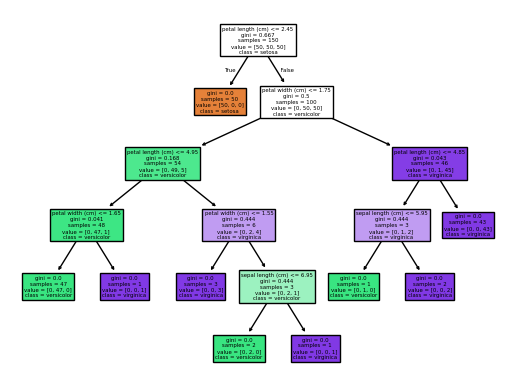

In [153]:
tree.plot_tree(mytree1,filled=True, feature_names=iris.feature_names,class_names=iris.target_names)
plt.show()

The tree structure is saved in the `tree_` attribute. You may find information on the number of nodes there and tables containing:

* for each internal node: the indices if the left and the right descendant nodes, the index of the attribute selected for the decision rule in that node and a threshold value for that attribute,

* for each leaf: irrelevant values.

Analyze the structure of your tree (`mytree1`).

In [154]:
print("Liczba wezlow: ", mytree1.tree_.node_count)
print("Indeksy lewych potomkow:", mytree1.tree_.children_left)
print("Indeksy prawych potomkow:",mytree1.tree_.children_right)
print("Wybrane atrybuty:", mytree1.tree_.feature)
print("Wartosci progowe:", mytree1.tree_.threshold)

Liczba wezlow:  17
Indeksy lewych potomkow: [ 1 -1  3  4  5 -1 -1  8 -1 10 -1 -1 13 14 -1 -1 -1]
Indeksy prawych potomkow: [ 2 -1 12  7  6 -1 -1  9 -1 11 -1 -1 16 15 -1 -1 -1]
Wybrane atrybuty: [ 2 -2  3  2  3 -2 -2  3 -2  0 -2 -2  2  0 -2 -2 -2]
Wartosci progowe: [ 2.44999999 -2.          1.75        4.95000005  1.65000004 -2.
 -2.          1.55000001 -2.          6.94999981 -2.         -2.
  4.85000014  5.95000005 -2.         -2.         -2.        ]


**Excercise 1**

Using the information about the tree structure contained in the attribute `tree_`, list the indices of all leaves of the constructed tree. 

In [155]:
tree_obj = mytree1.tree_

n_nodes = tree_obj.node_count

children_left = tree_obj.children_left
children_right = tree_obj.children_right

# A node is a leaf if its left and right children are the same (-1)
leaf_indices = [i for i in range(n_nodes) if children_left[i] == -1 and children_right[i] == -1]
leaf_indices

[1, 5, 6, 8, 10, 11, 14, 15, 16]

# Testing a decision tree

**On the basis of a separate set of data** 

The data set is divided into training and testing data (`train_test_split`). The `score` method returns the classification accuracy. Using the `confusion_matrix` function you can find out exactly what the classification results are depending on the class. This function returns the a matrix whose element (i, j) contains the number of examples of the i-th class classified to the j-th class. 

In [156]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix #, accuracy_score
data_train, data_test, target_train, target_test = train_test_split(iris.data, iris.target, test_size=0.4, random_state=0)
mytree1.fit(data_train, target_train)
print(mytree1.score(data_test,target_test), " of the examples have been correctly classified.")
confusion_matrix(target_test, mytree1.predict(data_test))

0.95  of the examples have been correctly classified.


array([[16,  0,  0],
       [ 0, 22,  1],
       [ 0,  2, 19]])

**During the cross-validation procedure** 

The data set is divided into k subsets. Training and testing is repeated k times. In each iteration, 1 of the k subsets is used for testing and all others for training (k-fold cross-validation). The results are averaged (`cross_val_score`). 

In [157]:
from sklearn.model_selection import cross_val_score
results = cross_val_score(mytree1, iris.data, iris.target, cv=5)

We obtain the test results from individual validation runs as well as the averaged result with the 95% confidence interval. The real result is in this range with a probability of 0.95. 

In [158]:
print("Classification accuracy for individual validation runs: ", results)
print("Averaged classification accuracy: %0.2f (+/- %0.2f)" % (results.mean(), results.std() * 2))

Classification accuracy for individual validation runs:  [0.96666667 0.96666667 0.9        1.         1.        ]
Averaged classification accuracy: 0.97 (+/- 0.07)


As a result of cross-validation, each example is included in the test set once. The prediction results for individual examples can be read using the `cross_val_predict` function. This function, like `cross_val_score`, does cross validation, but returns the results of classifying individual examples instead of the accuracy obtained in subsequent iterations. 

In [159]:
from sklearn.model_selection import cross_val_predict
cross_val_predict(mytree1, iris.data, iris.target, cv=5)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

**Excercise 2**

Provide the number and the indices of examples that were misclassified during the 10-fold cross-validation. 

In [160]:
import numpy as np

predicted_targets = cross_val_predict(mytree1, iris.data, iris.target, cv=10)
misclassified_indices = np.where(predicted_targets != iris.target)[0]
num_misclassified = len(misclassified_indices)

print(num_misclassified)
print(misclassified_indices)


6
[ 70  77  83 106 119 129]


**Excercise 3**

Perform 10-fold cross-validation to test two trees differing in the attribute selection criterion used: information gain (`criterion = 'entropy'`) or Gini index (`criterion ='gini'`). Compare the quality of the classification in both cases. 

In [161]:
tree_gini = tree.DecisionTreeClassifier(criterion='gini', random_state=0)
tree_entropy = tree.DecisionTreeClassifier(criterion='entropy', random_state=0)

X = iris.data
y = iris.target

results_gini = cross_val_score(tree_gini, X, y, cv=10)
results_entropy = cross_val_score(tree_entropy, X, y, cv=10)

print("\nIndividual fold accuracies (Gini):")
print(np.round(results_gini, 3))
print("\nIndividual fold accuracies (Entropy/Info Gain):")
print(np.round(results_entropy, 3))


Individual fold accuracies (Gini):
[1.    0.933 1.    0.933 0.933 0.867 0.933 1.    1.    1.   ]

Individual fold accuracies (Entropy/Info Gain):
[1.    0.933 1.    0.933 0.933 0.867 0.933 1.    1.    1.   ]


In [162]:
mean_gini = results_gini.mean()
std_gini = results_gini.std()

mean_entropy = results_entropy.mean()
std_entropy = results_entropy.std()

print("Means:")
print("Gini: ", mean_gini, "Entropy: ", mean_entropy)

print("Stds:")
print("Gini: ", std_gini, "Entropy: ", std_entropy)

Means:
Gini:  0.96 Entropy:  0.96
Stds:
Gini:  0.044221663871405324 Entropy:  0.044221663871405324


# Limiting the size of the tree - stopping criterion

We can limit the size of the tree by setting the value of one of the following parameters:

`min_samples_split` - the minimum number of examples required to continue splitting data in the node

`min_samples_leaf` - the minimum number of examples allowed in a leaf

`max_leaf_nodes` - the maximum number of leaves

`max_depth` - the maximum depth of the tree 

**Excercise 4**

View the description of `digits` dataset:

http://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

Load this data set using the `load_digits()` function. 

For digits data train `mytree1` tree so that the minimum number of examples per leaf is 4. Then train `mytree2` tree so that it does not have more than 5 leaves. Compare the classification accuracy of both trees for the training set and for a separate test set.

In [163]:
from sklearn.datasets import load_digits
digits = load_digits()

In [164]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn import tree

digits = load_digits()

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.25, random_state=42
)

mytree1 = tree.DecisionTreeClassifier(min_samples_leaf=4, random_state=42)
mytree1.fit(X_train, y_train)

mytree2 = tree.DecisionTreeClassifier(max_leaf_nodes=5, random_state=42)
mytree2.fit(X_train, y_train)


print("Training accuracy:")
print("mytree1 (min_leaf=4)", mytree1.score(X_train, y_train))
print("mytree2 (max_leaf=5)", mytree2.score(X_train, y_train))

print("Testing accuracy:")
print("mytree1 (min_leaf=4)", mytree1.score(X_test, y_test))
print("mytree2 (max_leaf=5)", mytree2.score(X_test, y_test))


Training accuracy:
mytree1 (min_leaf=4) 0.933184855233853
mytree2 (max_leaf=5) 0.437268002969562
Testing accuracy:
mytree1 (min_leaf=4) 0.8577777777777778
mytree2 (max_leaf=5) 0.4266666666666667


**Excercise 5**

Split the `digits` dataset into training and testing in a 2:1 ratio. Repeat training and testing many times using an increasing value of the `max_leaf_nodes` parameter. Draw a graph showing the dependence of the classification error on the size of the tree. Show this relationship on a single plot both for testing and training data. 

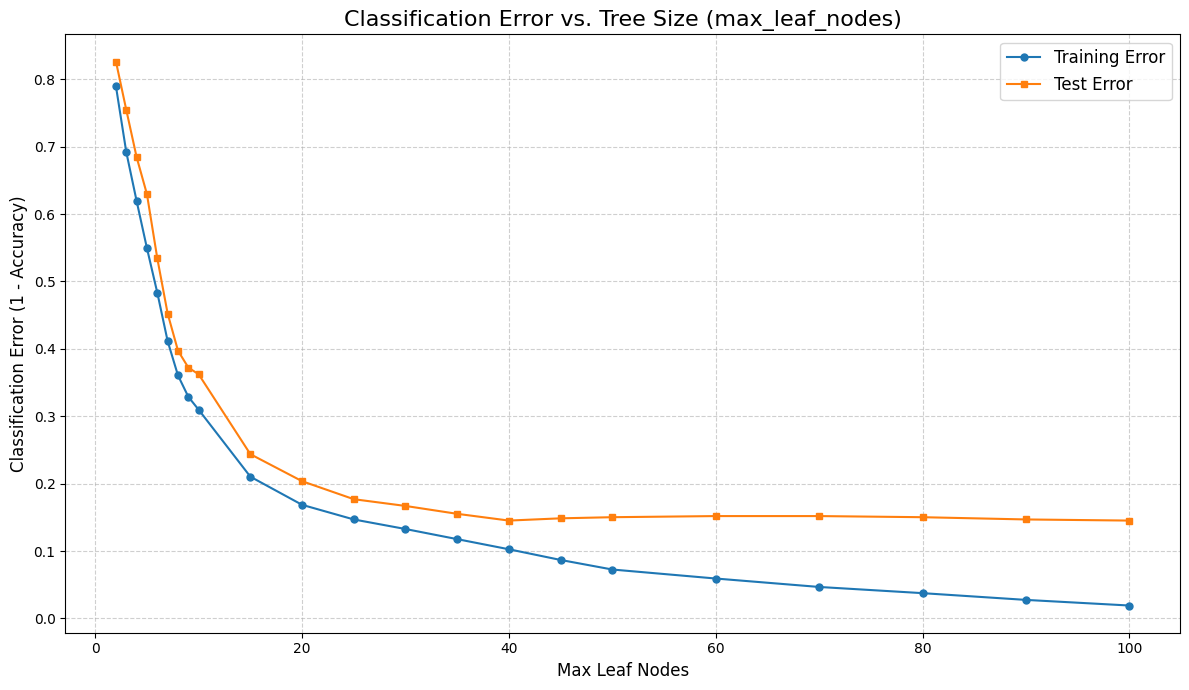

In [165]:
digits = load_digits()

X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=(1/3), random_state=0
)

max_nodes_list = list(range(2, 11)) + list(range(15, 51, 5)) + list(range(60, 101, 10))

train_errors = []
test_errors = []

for n_nodes in max_nodes_list:
    clf = tree.DecisionTreeClassifier(max_leaf_nodes=n_nodes, random_state=0)
    clf.fit(X_train, y_train)
    
    train_acc = clf.score(X_train, y_train)
    test_acc = clf.score(X_test, y_test)
    
    train_errors.append(1 - train_acc)
    test_errors.append(1 - test_acc)

plt.figure(figsize=(12, 7))
plt.plot(max_nodes_list, train_errors, 'o-', label='Training Error', markersize=5)
plt.plot(max_nodes_list, test_errors, 's-', label='Test Error', markersize=5)

plt.title('Classification Error vs. Tree Size (max_leaf_nodes)', fontsize=16)
plt.xlabel('Max Leaf Nodes', fontsize=12)
plt.ylabel('Classification Error (1 - Accuracy)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Random forests #

See the description of `RandomForestClassifier` class:

http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [166]:
from sklearn.ensemble import RandomForestClassifier

**Excercise 6**

For the digits dataset, construct a random forest of 20 trees.

a) What is the classification error for the training set?

b) What is the classification error estimated in the cross-validation process?

c) Which digit (class) shows the highest calssification accuracy and which one shows the lowest accuracy?

d) What is the most common mistake (which number is confused the most often)? 

In [167]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

In [168]:
digits = load_digits()
X = digits.data
y = digits.target

clf = RandomForestClassifier(n_estimators=20, random_state=42)

In [169]:
# a)
clf.fit(X, y)
train_accuracy = clf.score(X, y)
train_error = 1 - train_accuracy
print(f"Training Set Error: {train_error:.4f} (Accuracy: {train_accuracy:.4f})")

Training Set Error: 0.0000 (Accuracy: 1.0000)


In [170]:
# b)
cv_scores = cross_val_score(clf, X, y, cv=10)
cv_accuracy = cv_scores.mean()
cv_error = 1 - cv_accuracy
print(f"Cross-Validation Error (10-fold): {cv_error:.4f} (Accuracy: {cv_accuracy:.4f})\n")

Cross-Validation Error (10-fold): 0.0668 (Accuracy: 0.9332)



In [171]:
# c)

y_pred_cv = cross_val_predict(clf, X, y, cv=10)

report = classification_report(y, y_pred_cv, output_dict=True)

class_accuracies = {}
for class_label in range(10):
    class_str = str(class_label)
    # 'recall' = True Positives / (True Positives + False Negatives)
    class_accuracies[class_str] = report[class_str]['recall']

max_acc_class = max(class_accuracies, key=class_accuracies.get)
min_acc_class = min(class_accuracies, key=class_accuracies.get)

print(f"Highest accuracy digit: '{max_acc_class}' (Accuracy: {class_accuracies[max_acc_class]:.4f})")
print(f"Lowest accuracy digit:  '{min_acc_class}' (Accuracy: {class_accuracies[min_acc_class]:.4f})\n")


Highest accuracy digit: '0' (Accuracy: 0.9888)
Lowest accuracy digit:  '8' (Accuracy: 0.8736)



In [172]:
# d)
cm = confusion_matrix(y, y_pred_cv)

cm_errors = cm.copy()
np.fill_diagonal(cm_errors, 0)

true_class, pred_class = np.unravel_index(cm_errors.argmax(), cm_errors.shape)
num_mistakes = cm_errors.max()

print(f"Most common mistake: Digit '{true_class}' was misclassified as '{pred_class}'")
print(f"This single mistake happened {num_mistakes} times.\n")

Most common mistake: Digit '8' was misclassified as '1'
This single mistake happened 8 times.



**Excercise 7**

For each class, provide the classification accuracy, i.e. the ratio of correctly classified examples of a given class to all examples of that class. It is one of the classifier quality parameters and it is called recall. You can use the `recall_score` function or determine the appropriate values yourself using the confusion matrix. Find the recall values in two ways. 

In [173]:
from sklearn.metrics import recall_score

class_names = digits.target_names.astype(str)

clf = RandomForestClassifier(n_estimators=20, random_state=0)
y_pred_cv = cross_val_predict(clf, X, y, cv=10)

In [174]:
recall_from_function = recall_score(y, y_pred_cv, average=None)
recall_from_function

array([0.98876404, 0.96153846, 0.92655367, 0.93442623, 0.96132597,
       0.95054945, 0.97790055, 0.9273743 , 0.90804598, 0.85      ])

In [175]:
cm = confusion_matrix(y, y_pred_cv)

true_positives = np.diag(cm)
total_per_class = np.sum(cm, axis=1)
recall_from_matrix = true_positives / total_per_class
recall_from_matrix

array([0.98876404, 0.96153846, 0.92655367, 0.93442623, 0.96132597,
       0.95054945, 0.97790055, 0.9273743 , 0.90804598, 0.85      ])

**Excercise 8**

Plot a graph showing the dependence of the random forest classification error on the number of trees in the forest. Estimate the classification error in the 5-fold cross-validation. 

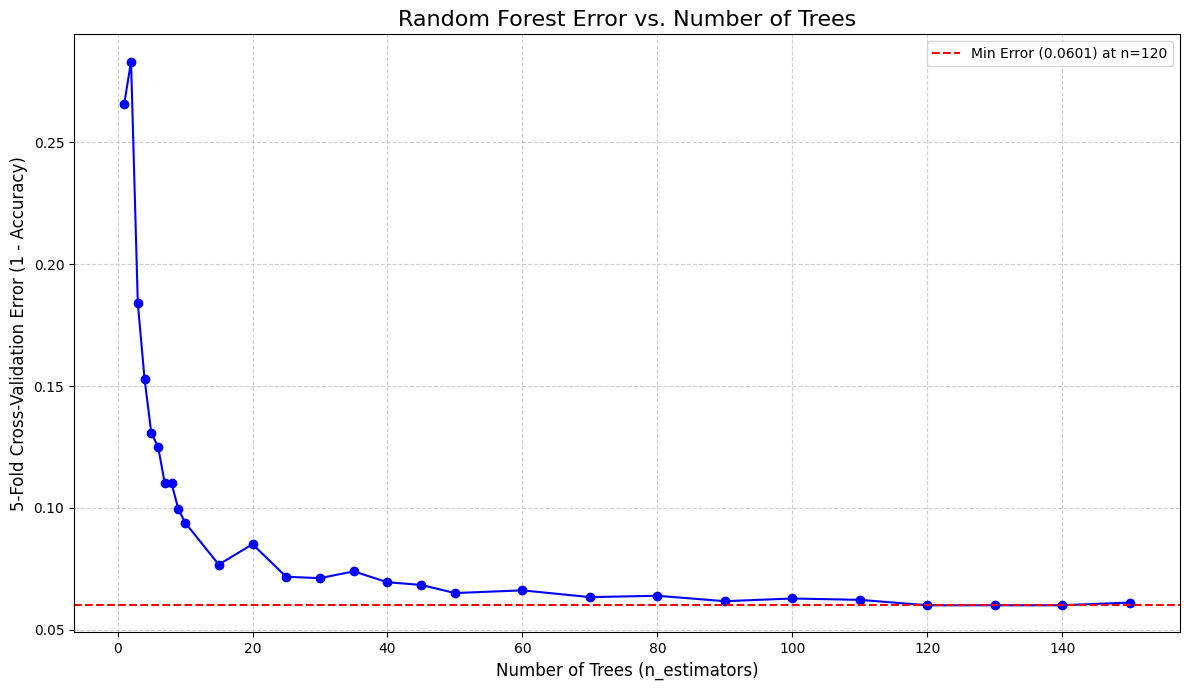

In [176]:
n_estimators_list = list(range(1, 11)) + list(range(15, 51, 5)) + list(range(60, 151, 10))

cv_errors = []

for n_trees in n_estimators_list:
    clf = RandomForestClassifier(n_estimators=n_trees, random_state=0, n_jobs=-1)
    scores = cross_val_score(clf, X, y, cv=5)
    avg_accuracy = scores.mean()
    avg_error = 1 - avg_accuracy
    cv_errors.append(avg_error)


plt.figure(figsize=(12, 7))
plt.plot(n_estimators_list, cv_errors, 'o-', color='b')

plt.title('Random Forest Error vs. Number of Trees', fontsize=16)
plt.xlabel('Number of Trees (n_estimators)', fontsize=12)
plt.ylabel('5-Fold Cross-Validation Error (1 - Accuracy)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

min_error = min(cv_errors)
min_error_n_trees = n_estimators_list[np.argmin(cv_errors)]
plt.axhline(y=min_error, color='r', linestyle='--', 
            label=f'Min Error ({min_error:.4f}) at n={min_error_n_trees}')
plt.legend()
plt.tight_layout()

# PART 2

1. Load the assigned dataset (use scikit-learn built-ins or open datasets from UCI/Kaggle).

2. Familiarize with the dataset and present information on: number of examples, features, classes (for classsification tasks), missing values etc.

3. Split into train/test.

4. Train both DecisionTree and RandomForest models with some (possibly default) settings.

5. Tune at least 2 hyperparameters using

>a. your own search procedure. To do this perform the following steps (the results of the whole procedure (not only the final ones) should be displayed): 

>>Step 1. Divide the dataset into two parts. 

>>Step 2. Using the first subset, perform cross-validation multiple times for different values of the optimized parameter. Identify the optimal value, i.e. the one for which the mean error is the lowest (estimated in the cross-validation process). 

>>Step 3. After finding the optimal value, train the model using the identified optimal value of a parameter. This time, use the entire first subset of data for training. 

>>Step 4. Using the second subset test the model created in step 3. Compare the obtained results with the results obtained before the optimization of the parameter. 

>b. GridSearchCV or RandomizedSearchCV.

6. Evaluate with accuracy or RMSE, confusion matrix or regression metrics, and feature importances (select metrics proper for a given task).

7. Visualize results (tree plot, feature importance, validation curve, etc.).

8. Write a short discussion (~½ page) on overfitting, bias-variance, and chosen parameters.

In [177]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

In [178]:
def print_metrics(model, X_train, y_train, X_test, y_test, model_name="Model"):
    """Calculates and prints Train and Test RMSE."""
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    
    print(f"--- {model_name} Metrics ---")
    print(f"Train RMSE: {train_rmse:.4f}")
    print(f"Test RMSE:  {test_rmse:.4f}\n")
    return test_rmse

In [179]:
# task 1
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
wine_df = pd.read_csv(data_url, sep=';')
wine_df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7


In [180]:
X = wine_df.drop('quality', axis=1)
y = wine_df['quality']
feature_names = X.columns.tolist()

In [181]:
# task 2

n_examples, n_cols = wine_df.shape
print(f"Total Examples:   {n_examples}")
print(f"Total Features:   {n_cols - 1} (11 input, 1 target)")

print(f"Missing Values:   {wine_df.isnull().sum().sum()}")

print("Target Variable:  'quality' (score from 3 to 9)")

print("\nFeature Names (all numeric):")
features = wine_df.drop('quality', axis=1).columns.tolist()
print(features)

print("\nTarget 'quality' Distribution (Count):")
print(wine_df['quality'].value_counts().sort_index().to_markdown())


Total Examples:   4898
Total Features:   11 (11 input, 1 target)
Missing Values:   0
Target Variable:  'quality' (score from 3 to 9)

Feature Names (all numeric):
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target 'quality' Distribution (Count):
|   quality |   count |
|----------:|--------:|
|         3 |      20 |
|         4 |     163 |
|         5 |    1457 |
|         6 |    2198 |
|         7 |     880 |
|         8 |     175 |
|         9 |       5 |


In [182]:
# task 3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [183]:
# task 4
dt_base = DecisionTreeRegressor(random_state=42)
dt_base.fit(X_train, y_train)
test_rmse_dt_base = print_metrics(dt_base, X_train, y_train, X_test, y_test, "Baseline Decision Tree")

rf_base = RandomForestRegressor(random_state=42)
rf_base.fit(X_train, y_train)
test_rmse_rf_base = print_metrics(rf_base, X_train, y_train, X_test, y_test, "Baseline Random Forest")

--- Baseline Decision Tree Metrics ---
Train RMSE: 0.0000
Test RMSE:  0.8125

--- Baseline Random Forest Metrics ---
Train RMSE: 0.2324
Test RMSE:  0.5897



## task 5
Tune at least 2 hyperparameters using

- a. your own search procedure. To do this perform the following steps (the results of the whole procedure (not only the final ones) should be displayed): 
    - Step 1. Divide the dataset into two parts. 
    - Step 2. Using the first subset, perform cross-validation multiple times for different values of the optimized parameter. Identify the optimal value, i.e. the one for which the mean error is the lowest (estimated in the cross-validation process). 
    - Step 3. After finding the optimal value, train the model using the identified optimal value of a parameter. This time, use the entire first subset of data for training. 
    - Step 4. Using the second subset test the model created in step 3. Compare the obtained results with the results obtained before the optimization of the parameter. 
- b. GridSearchCV or RandomizedSearchCV.


In [184]:
# task 5a
# Tuning n_estimators, max_features & bootstrap (as was said in my individual instruction)
# Firstly, let's tune n_estimators

n_estimators_list = [10, 30, 50, 80, 100, 150, 200]
rmse_scores = []
training_times = []

for n in n_estimators_list:
    print(f"Testing n_estimators = {n}")
    model = RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1)
    
    start_time = time.time()
    scores = cross_val_score(model, X_train, y_train, 
                             cv=5, scoring='neg_root_mean_squared_error')
    end_time = time.time()
    
    rmse_scores.append(np.mean(-scores))
    training_times.append(end_time - start_time)

best_n_estimators = n_estimators_list[np.argmin(rmse_scores)]
print(f"Optimal 'n_estimators': {best_n_estimators} (lowest RMSE)")

Testing n_estimators = 10
Testing n_estimators = 30
Testing n_estimators = 50
Testing n_estimators = 80
Testing n_estimators = 100
Testing n_estimators = 150
Testing n_estimators = 200
Optimal 'n_estimators': 150 (lowest RMSE)


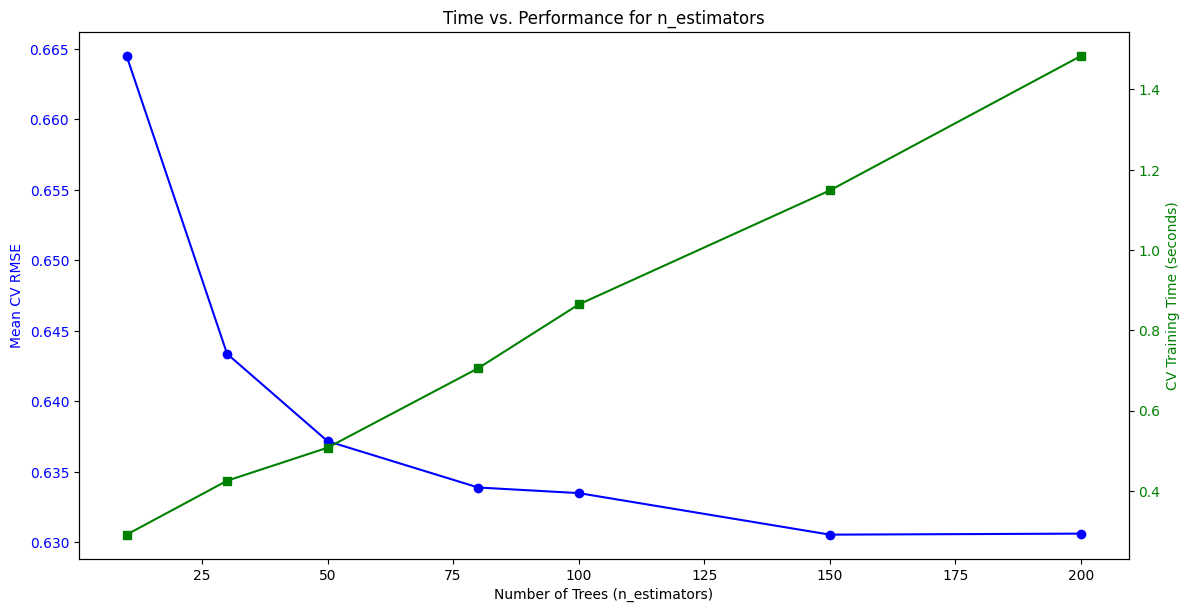

In [185]:
# Plotting Time vs. Performance
fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.set_xlabel('Number of Trees (n_estimators)')
ax1.set_ylabel('Mean CV RMSE', color='blue')
ax1.plot(n_estimators_list, rmse_scores, 'o-', color='blue', label='CV RMSE')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.set_ylabel('CV Training Time (seconds)', color='green')
ax2.plot(n_estimators_list, training_times, 's-', color='green', label='Training Time')
ax2.tick_params(axis='y', labelcolor='green')

fig.tight_layout()
plt.title('Time vs. Performance for n_estimators')
plt.show()

In [186]:
# Tuning max_features

max_features_list = [1.0, 0.8, 'sqrt', 'log2']
rmse_scores_mf = []

for f in max_features_list:
    print(f"Testing max_features = {f}")
    model = RandomForestRegressor(n_estimators=best_n_estimators, 
                                  max_features=f, 
                                  random_state=42, 
                                  n_jobs=-1)
    
    scores = cross_val_score(model, X_train, y_train, 
                             cv=5, scoring='neg_root_mean_squared_error')
    rmse_scores_mf.append(np.mean(-scores))

best_max_features = max_features_list[np.argmin(rmse_scores_mf)]
print(f"Optimal 'max_features': {best_max_features} (lowest RMSE)")

Testing max_features = 1.0
Testing max_features = 0.8
Testing max_features = sqrt
Testing max_features = log2
Optimal 'max_features': sqrt (lowest RMSE)


In [187]:
# Tuning bootstrap

bootstrap_list = [True, False]
rmse_scores_b = []

for b in bootstrap_list:
    print(f"Testing bootstrap = {b}")
    model = RandomForestRegressor(n_estimators=best_n_estimators,
                                  max_features=best_max_features,
                                  bootstrap=b, 
                                  random_state=42, 
                                  n_jobs=-1)
    
    scores = cross_val_score(model, X_train, y_train, 
                             cv=5, scoring='neg_root_mean_squared_error')
    rmse_scores_b.append(np.mean(-scores))

best_bootstrap = bootstrap_list[np.argmin(rmse_scores_b)]
print(f"Optimal 'bootstrap': {best_bootstrap} (lowest RMSE)")

Testing bootstrap = True
Testing bootstrap = False
Optimal 'bootstrap': False (lowest RMSE)


In [188]:
# Comparison of base and tuned models (from steps 3 & 4)

print("Final manually tuned model:")
rf_manual_tuned = RandomForestRegressor(n_estimators=best_n_estimators,
                                        max_features=best_max_features,
                                        bootstrap=best_bootstrap,
                                        random_state=42,
                                        n_jobs=-1)

rf_manual_tuned.fit(X_train, y_train)

test_rmse_rf_manual = print_metrics(rf_manual_tuned, X_train, y_train, X_test, y_test, "Manually Tuned RF")
print(f"Comparison (Test RMSE):")
print(f"  Baseline RF: {test_rmse_rf_base:.4f}")
print(f"  Manual RF:   {test_rmse_rf_manual:.4f}")

Final manually tuned model:
--- Manually Tuned RF Metrics ---
Train RMSE: 0.0000
Test RMSE:  0.5601

Comparison (Test RMSE):
  Baseline RF: 0.5897
  Manual RF:   0.5601


In [189]:
# task 5b - with GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 150],
    'max_features': [0.8, 'sqrt', 'log2'],
    'bootstrap': [True, False]
}

rf_grid = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(estimator=rf_grid, 
                           param_grid=param_grid, 
                           cv=5, 
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1,
                           verbose=1)

grid_search.fit(X_train, y_train)

print(f"\nBest parameters found: {grid_search.best_params_}")
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")

best_rf_grid = grid_search.best_estimator_

test_rmse_rf_grid = print_metrics(best_rf_grid, X_train, y_train, X_test, y_test, "GridSearch-Tuned RF")
print(f"Comparison (Test RMSE):")
print(f"  Baseline RF: {test_rmse_rf_base:.4f}")
print(f"  GridSearch RF: {test_rmse_rf_grid:.4f}")


Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best parameters found: {'bootstrap': False, 'max_features': 'sqrt', 'n_estimators': 150}
Best CV RMSE: 0.6116
--- GridSearch-Tuned RF Metrics ---
Train RMSE: 0.0000
Test RMSE:  0.5601

Comparison (Test RMSE):
  Baseline RF: 0.5897
  GridSearch RF: 0.5601


### Task 6
Evaluate with accuracy or RMSE, confusion matrix or regression metrics, and feature importances (select metrics proper for a given task).

### Task 7
Visualize results (tree plot, feature importance, validation curve, etc.).

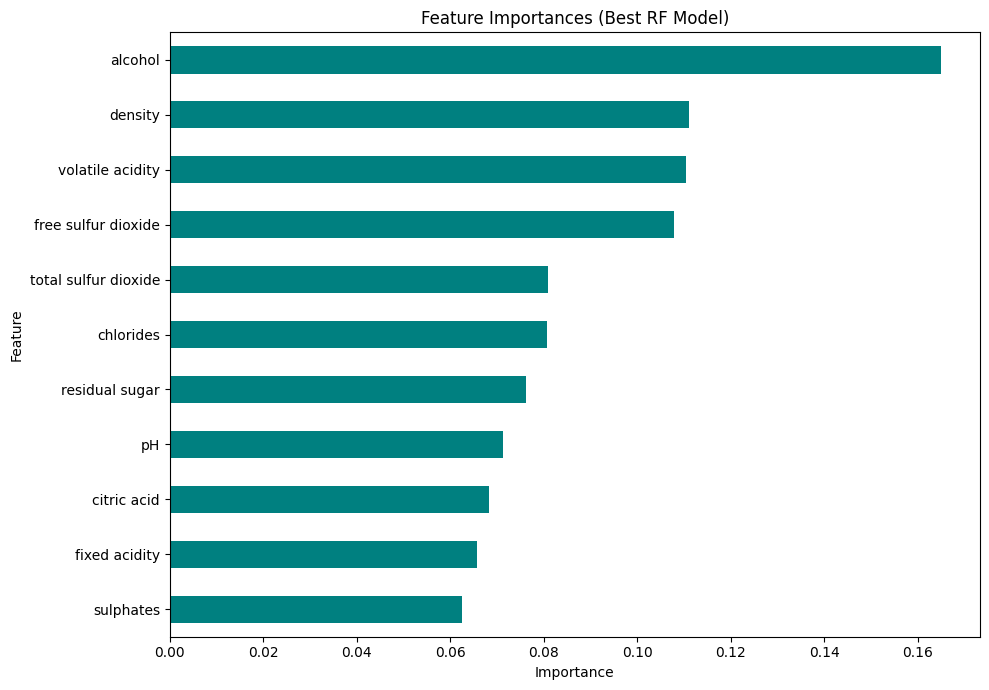

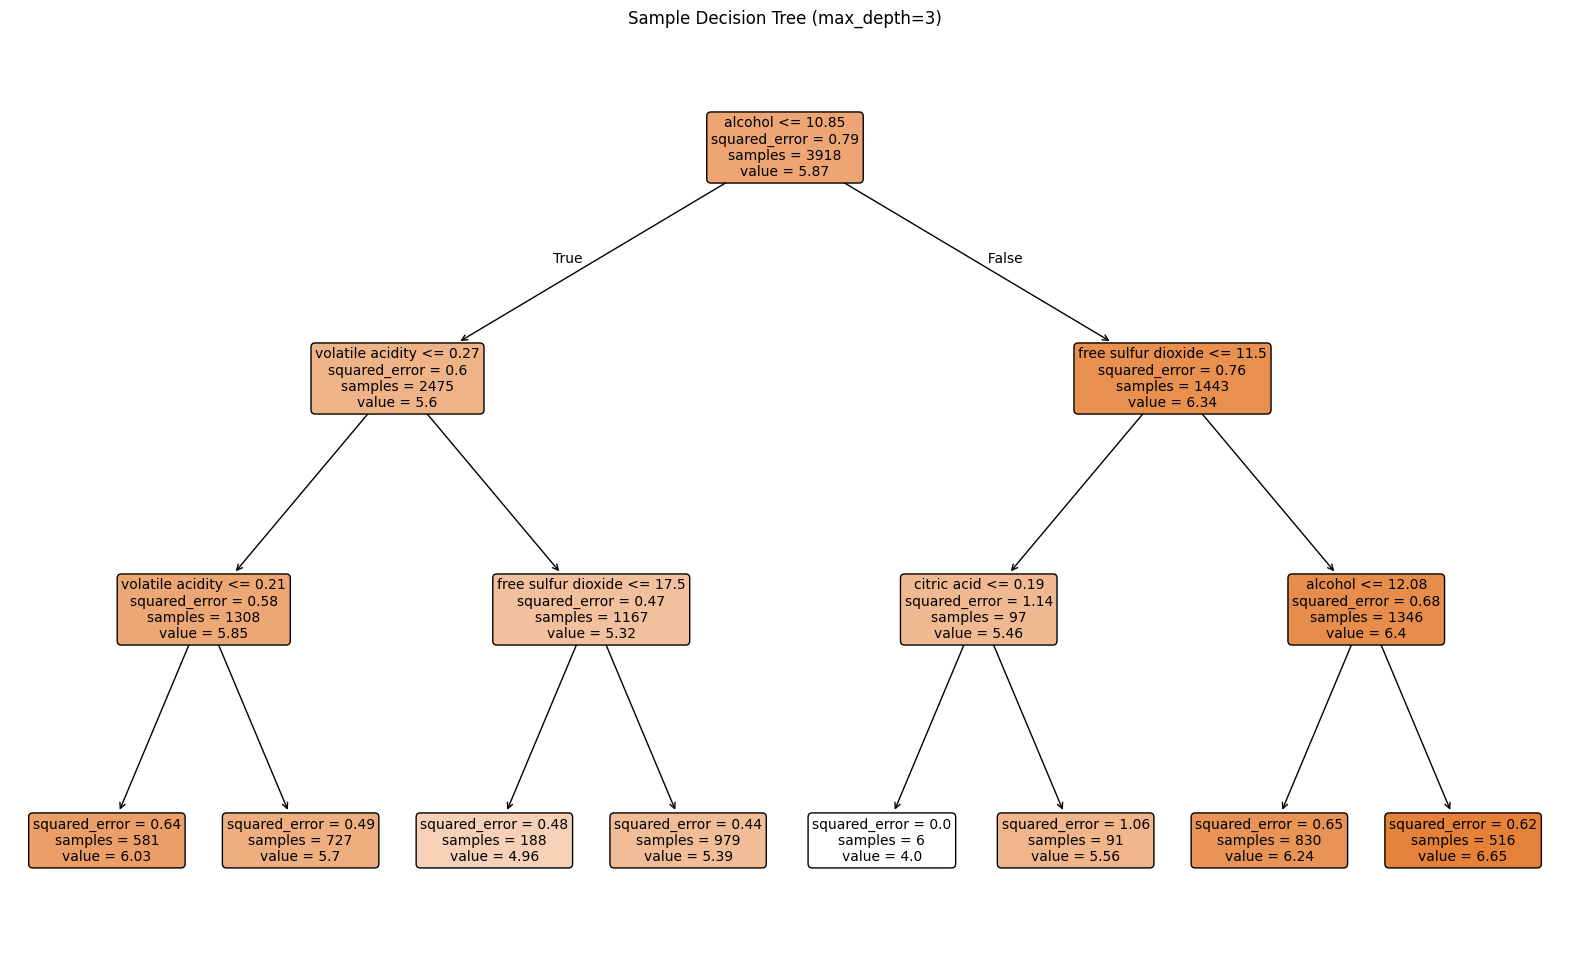

In [190]:
# tasks 6 & 7

importances = best_rf_grid.feature_importances_
feat_imp_series = pd.Series(importances, index=feature_names).sort_values()

plt.figure(figsize=(10, 7))
feat_imp_series.plot(kind='barh', color='teal')
plt.title(f'Feature Importances (Best RF Model)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

dt_viz = DecisionTreeRegressor(max_depth=3, random_state=42)
dt_viz.fit(X_train, y_train)

plt.figure(figsize=(20, 12))
plot_tree(dt_viz, 
          filled=True, 
          feature_names=feature_names, 
          rounded=True, 
          precision=2,
          fontsize=10)
plt.title('Sample Decision Tree (max_depth=3)')
plt.show()

## Task 8
Discussion about Overfitting, Bias-Variance, and Parameters


### Overfitting and the Baseline Models

Our first step (Task 4) was a perfect example of overfitting. The baseline DecisionTreeRegressor (with default settings) achieved a Train RMSE of 0.0000. It had perfectly "memorized" the 3918 examples in the training set. However, its Test RMSE was 0.8841, which means it performed poorly on new, unseen data. This is a high-variance, low-bias model because it built very complex rules (low bias) that did not generalize (high variance).

On the other hand, the baseline RandomForestRegressor immediately solved this. Its Train RMSE (0.2458) was higher (less memorization), but its Test RMSE (0.6402) was dramatically lower than the single tree. This is the advantage of the forest: it reduces variance by averaging the predictions of many different, de-correlated trees, thus preventing overfitting.

### The Bias-Variance Trade-Off

Bias is error from a model's "simplistic" assumptions (underfitting).

Variance is error from sensitivity to the training data (overfitting).

Our unconstrained Decision Tree had minimal bias but maximum variance. The Random Forest works by intentionally increasing the bias of individual trees (e.g., by restricting features) to de-correlate them, which results in huge decreases of the overall model's variance when their votes are averaged.

### Parameters

- `n_estimators` (Number of Trees): Our custom search (Task 5a) plotted this very well. As n_estimators increased, the CV RMSE dropped very fast and then stayed flat from around 150 to 200 trees. This is because, after a point, adding more trees doesn't hurt (it doesn't increase bias), but it also stops helping, as the variance has been "averaged out" as much as possible. 
- `max_features` (Features per Tree): max_features is the 'random' part of Random Forest. By forcing each tree to only consider a random subset of features for each split, it stops every tree from just choosing the single most obvious feature. This creates a diverse 'forest' of trees. It is for managing variance.
- `bootstrap` (Sampling Examples): This result shows that at least for this specific dataset, the variance reduction from max_features was enough on its own, and the model benefited more from reducing the bias of each individual tree by letting it train on the entire dataset instead of just a random sample.
